# Penguin or Ostrich? Image Binary Classification with FAST AI

In this notebook, you will plan and build a small image classifier that distinguishes whether a photo is of a penguin or an ostrich following the lesson from Practical Deep Learning for Coders Lesson 1 on FastAI.

This is a practice project, not a promise of any particular accuracy. Results depend on the images, labels, training setup, and evaluation data you choose.

Run each cell of code one at a time.

In [2]:
!pip install -Uqq fastai ddgs

## What you will learn

By the end, you should be able to:

- Describe binary image classification as choosing between two labels.
- Organize labeled images in a folder structure that fastai can read.
- Create data loaders and train a transfer-learning image classifier.
- Read a confusion matrix and inspect individual predictions.
- Identify common sources of misleading evaluation results.

The positive label is **ostrich** and the other label is **penguin**. Keep those names consistent in folder names, output interpretation, and your notes.

## Before you begin

You should be comfortable opening a notebook, running Python cells, and reading basic Python values. You do not need to know how neural networks work in detail; the exercise will introduce the main steps.

This project uses the fastai. Set up an environment with fastai installed, following the [fastai installation guide](https://docs.fast.ai/). Image model training may use a GPU when one is available, but a small experiment can also run on a CPU more slowly, a better way is to use Google Colab or Kaggle Notebooks.

In [3]:
from ddgs import DDGS
from fastcore.all import *

def search_images(term, max_images=200):
    with DDGS() as ddgs:
        results = ddgs.images(
            term,
            max_results=max_images
        )

    urls = [result['image'] for result in results if result.get('image')]

    return L(urls[:max_images])

In [4]:
urls = search_images('penguin_photos', max_images=1)
urls[0]

'https://images.pexels.com/photos/35063543/pexels-photo-35063543.jpeg?cs=srgb&dl=pexels-jan-tang-598592438-35063543.jpg&fm=jpg'

click on the link to download the image and look at it

## 1. Find and prepare image data

We'll simply collect the images of penguins and ostriches using fast ai.

Then create a dataset directory with one subfolder per class. A folder-based dataset commonly looks like this:

```text
images/
  penguin/
    penguin-001.jpg
    penguin-002.jpg
  ostrich/
    ostrich-001.jpg
    ostrich-002.jpg
```

The folder names will act as labels. Make sure each image is in the correct folder.

We'll download one penguin and one ostrich photo first to look at what we'll be working with.

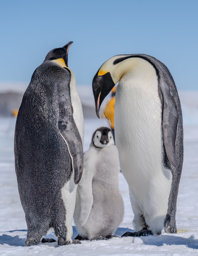

In [5]:
from fastdownload import download_url
dest = "penguin.jpg"
download_url(urls[0], dest, show_progress=False)

from fastai.vision.all import *
ls = Image.open(dest)
ls.to_thumb(256,256)

We'll grab an ostrich photo next!

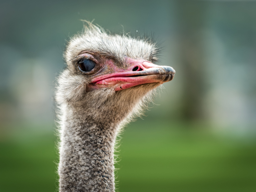

In [6]:
download_url(search_images('ostrich photos', max_images=1)[0], 'ostrich.jpg', show_progress=False)
Image.open('ostrich.jpg').to_thumb(256,256)

Now lets grab 200 of each "penguin" and "ostrich" photos

In [7]:
searches = "penguin", "ostrich"
path = Path('penguin_or_ostrich')

for o in searches:
    dest = (path/o)
    dest.mkdir(exist_ok=True, parents=True)
    download_images(dest, urls=search_images(f'{o} photos'))
    resize_images(path/o, max_size=400, dest=path/o)

Check the folder to see that there are two folders which have our ostrich and penguin photos

In [8]:
%ls penguin_or_ostrich

ostrich/  penguin/


Before training, we'll remove any failed downloads.

In [10]:
failed = verify_images(get_image_files(path))
failed.map(Path.unlink)
len(failed)

0

## 2. Create training and validation data

A **training set** is used to update the model. A separate **validation set** is used to check how well the trained model predicts images it did not train on.

Use fastai's folder-based image data loading tools to create a `DataLoaders` object. Choose a validation split and image size that your machine can handle. Review a batch to confirm that the images and labels look right before training.

Add your code to:

1. Point fastai at the dataset directory.
2. Create training and validation loaders from the class subfolders.
3. Resize or crop images as needed for the model.
4. Inspect a batch of images and their labels.

Keep validation images out of training. If multiple images come from the same original photo, video, or individual animal, consider splitting by source or group so similar images cannot leak across the split.

In [22]:
print("Path:", path)
print("Images:", len(get_image_files(path)))
print("Categories:", set(f.parent.name for f in get_image_files(path)))

Path: penguin_or_ostrich
Images: 67
Categories: {'ostrich', 'penguin'}


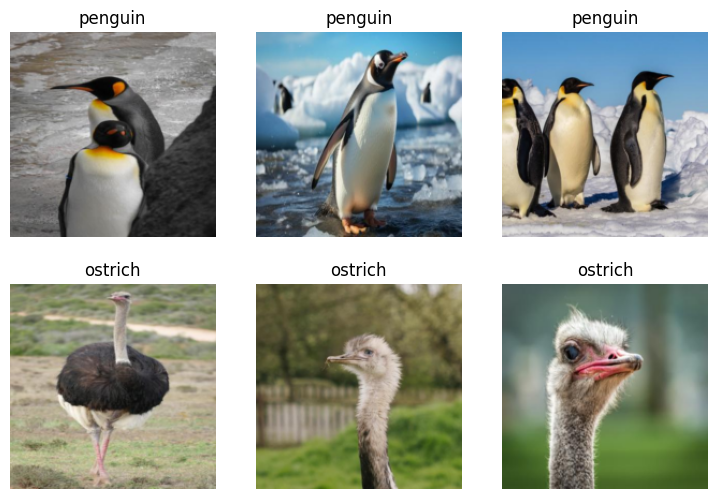

In [21]:
dls = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_items=get_image_files,
    splitter=RandomSplitter(valid_pct=0.2, seed=42),
    get_y=parent_label,
    item_tfms=Resize(192, method='squish')
).dataloaders(path, bs=32)

dls.show_batch(max_n=6)

## 3. Train a baseline classifier

Start with a fastai vision learner using a pretrained image model and a suitable binary-classification loss. Fine-tuning begins with learned visual features from the pretrained model and adapts them to your two classes.

Add code to create the learner, train for a small number of epochs, and record the training configuration. Follow the fastai lesson or API documentation for the exact calls. Start with a manageable experiment rather than searching for the best settings immediately.

After the first run, note the training and validation losses. A lower training loss alone does not mean the classifier will work well on new images.

In [24]:
learn = vision_learner(dls, resnet18, metrics=error_rate)
learn.fine_tune(3)

epoch,train_loss,valid_loss,error_rate,time
0,1.124044,3.081721,0.615385,00:06


epoch,train_loss,valid_loss,error_rate,time
0,1.318787,1.830559,0.615385,00:08
1,0.886520,0.307360,0.076923,00:08
2,0.629692,0.116294,0.076923,00:09


Let's prepare a new datablock with image transformation so see how the model will perform

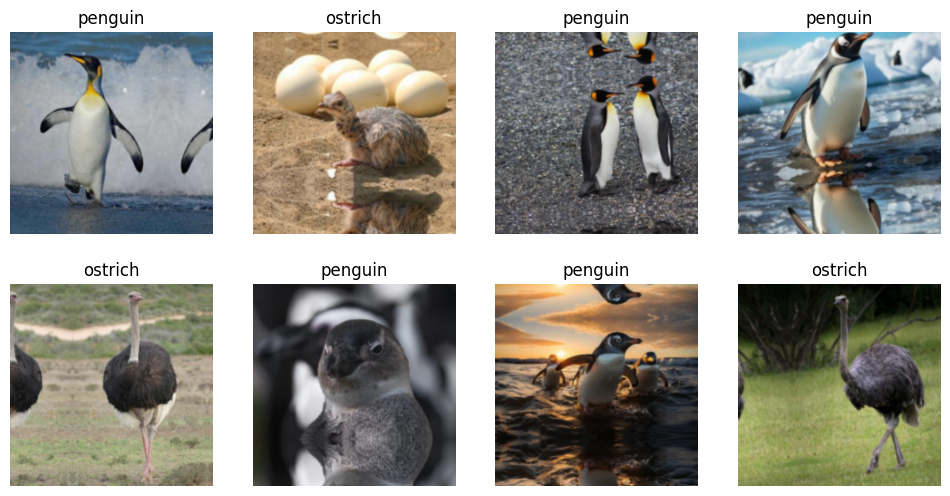

In [26]:
dls_new = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_items=get_image_files,
    splitter=RandomSplitter(valid_pct=0.2, seed=42),
    get_y=parent_label,
    item_tfms=Resize(224, method=ResizeMethod.Pad),
    batch_tfms=aug_transforms(
        do_flip=True,
        max_rotate=10,
        max_zoom=1.1,
        max_lighting=0.2,
        max_warp=0.0
    )
)

dls_new = dls_new.dataloaders(path, bs=16)

dls_new.show_batch(max_n=8)

In [28]:
learn = vision_learner(dls_new, resnet18, metrics=error_rate)
learn.fine_tune(3)

epoch,train_loss,valid_loss,error_rate,time
0,0.968406,0.817906,0.384615,00:11


epoch,train_loss,valid_loss,error_rate,time
0,0.129601,0.160654,0.076923,00:16
1,0.104831,0.014561,0.000000,00:16
2,0.082734,0.006399,0.000000,00:15


Now the model looks better, let's test it against some images

In [43]:
is_penguin,_,probs = learn.predict(PILImage.create('penguin.jpg'))

print(f'This is a: {is_penguin}')
print(f'Probability its a penguin: {probs[1]:.4f}')
print(f'Probability its an ostrich: {probs[0]:.4f}')

This is a: penguin
Probability its a penguin: 1.0000
Probability its an ostrich: 0.0000


In [44]:
is_ostrich,_,probs = learn.predict(PILImage.create('ostrich.jpg'))

print(f'This is a: {is_ostrich}')
print(f'Probability its a penguin: {probs[1]:.4f}')
print(f'Probability its an ostrich: {probs[0]:.4f}')

This is a: ostrich
Probability its a penguin: 0.0000
Probability its an ostrich: 1.0000


## 4. Evaluate the classifier

Check the classifier's validation results. Use a confusion matrix to see which class is mistaken for the other, and inspect examples of incorrect predictions. If appropriate for your use case, also examine precision and recall for each class.

Ask:

- How many penguins were predicted as ostriches, and how many ostriches as penguins?
- Does one class have fewer examples or substantially worse results?
- Are errors associated with image quality, unusual poses, backgrounds, or mislabeled data?
- Is the validation set large and varied enough to support your conclusions?

Add code to display the confusion matrix and review the most informative errors. Do not interpret one small validation score as proof that the model will generalize to every image source or setting.

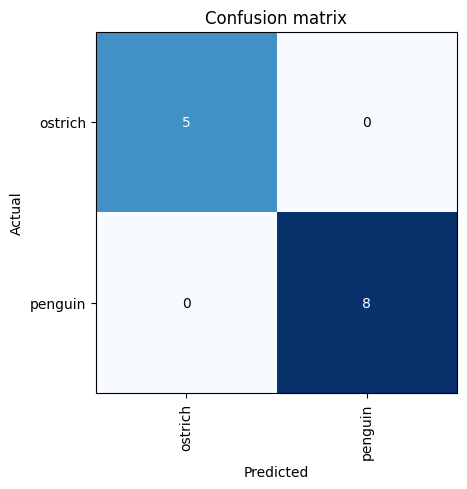

In [45]:
interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix()

Here's the confusion matrix and a simple prompt you can paste to any LLM to help inspect errors. Simply screenshot the confusion matrix, and paste into chatgpt along with this prompt

----
Analyze the confusion matrix for this classification model.

Explain:
1. The number of correct and incorrect predictions.
2. How well the model performs for each class.
3. Which classes the model confuses most often.
4. What the results reveal about the model's overall performance.
5. Potential areas for improvement.

Keep the analysis simple, clear, and beginner-friendly. Avoid unnecessary technical jargon. Base your conclusions strictly on the confusion matrix provided. 
____

Here's the analysis of the one above

## Confusion Matrix Analysis

100% accuracy on this validation set

### 1. Correct and incorrect predictions

The model made 13 predictions in total.

- Correct predictions: 13
- Incorrect predictions: 0
- Accuracy: 100%

### 2. Performance for each class

| Actual class | Correctly classified | Misclassified | Accuracy |
| ------------ | -------------------- | ------------- | -------- |
| Ostrich      | 5                    | 0             | 100%     |
| Penguin      | 8                    | 0             | 100%     |

- Ostrich: All 5 ostrich images were correctly classified.
- Penguin: All 8 penguin images were correctly classified.

### 3. Class confusion

The model did not confuse any ostriches with penguins or any penguins with ostriches.

Both off-diagonal values are zero, meaning there were no classification errors in this validation set.

### 4. Overall performance

The model achieved 100% validation accuracy, correctly identifying all 13 images.

This is an excellent initial result. However, it does not necessarily mean the model will achieve 100% accuracy on completely new images.

### 5. Potential areas for improvement

- Test with more images to assess generalization.
- Include different animal ages, poses, backgrounds and lighting conditions.
- Test on images the model has never encountered.
- Check for duplicate or very similar images between training and validation sets.

Conclusion: The model correctly classified every image in the validation set, demonstrating promising initial performance. However, a larger and more diverse test dataset is needed before concluding that the model is consistently reliable.

My advice: Don't celebrate the 100% just yet 😂. You have only 13 validation images. It's a promising result, but you need a bigger test set to establish how well your model actually generalizes.

# Note
ResNet18 isn't specifically designed to recognize penguins or ostriches. It's a general-purpose image classification architecture. We adapt it to recognize those two categories through transfer learning.

# More Work

Try the model against a bigger test set and see how well it performs

## Common mistakes to watch for

- **Inconsistent class names:** use `penguin` and `ostrich` consistently, and verify which label the library treats as each class.
- **Data leakage:** near-duplicates or images from the same source can make validation performance look better than performance on genuinely new data.
- **Class imbalance:** a model can achieve a deceptively high accuracy by mostly predicting the larger class.
- **Shortcut learning:** the model may associate a background, watermark, or camera style with a label instead of learning useful animal features.
- **Overfitting:** a model can improve on training images while getting worse on unseen images.
- **Unclear test data:** repeatedly tuning against the same validation examples can make them part of the development process; keep a final test set untouched if you need an unbiased final estimate.
- **Unsupported conclusions:** a small or narrowly sourced dataset cannot establish performance in every real-world setting.